# Lab 3 — Supervised Learning: Regression Algorithms
**Student:** Zeynep Ozdemir
**Student ID:** 9045142 
**Section:** Section 1

**Objective:** (A) Identify fraudulent credit-card transactions with
logistic regression; (B) predict insurance charges using linear regression.
For both models, use a 70/30 train/test split and evaluate performance.



In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
    classification_report, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    mean_absolute_error, mean_squared_error, r2_score)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


# PART A — CREDIT CARD FRAUD DETECTION

## Exploratory Data Analysis (EDA) and Data Preprocessing Checks
In this section, I am loading the dataset and performing Exploratory Data Analysis (EDA) by inspecting the DataFrame, checking null values and duplicated rows. I also check the data before preprocessing, identify the classification labels, and calculate the percentages of fraudulent and legitimate transactions. The results show that the dataset is highly imbalanced, with 99.827% legitimate transactions and only 0.173% fraudulent transactions.

In [12]:
fraud_df = pd.read_csv('data/creditcard.csv')
print('Shape:', fraud_df.shape)
display(fraud_df.head())
fraud_df.info()
print('Missing values:', fraud_df.isnull().sum().sum())
print('Duplicate rows:', fraud_df.duplicated().sum())
print('Class counts:')
print(fraud_df['Class'].value_counts())
print('Class percentages:')
print((fraud_df['Class'].value_counts(normalize=True)*100).round(3))


Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

Based on the Kaggle dataset information, Class 0 represents legitimate transactions, while Class 1 represents fraudulent transactions.

# Class Distribution Visualization

In this section, I am visualizing and comparing legitimate and fraudulent transactions using a count plot. The graph shows that legitimate transactions (Class 0) are much higher than fraudulent transactions (Class 1), which makes the fraud bar almost invisible. This indicates that the dataset is highly imbalanced, and accuracy alone may not be enough to evaluate the fraud detection model.

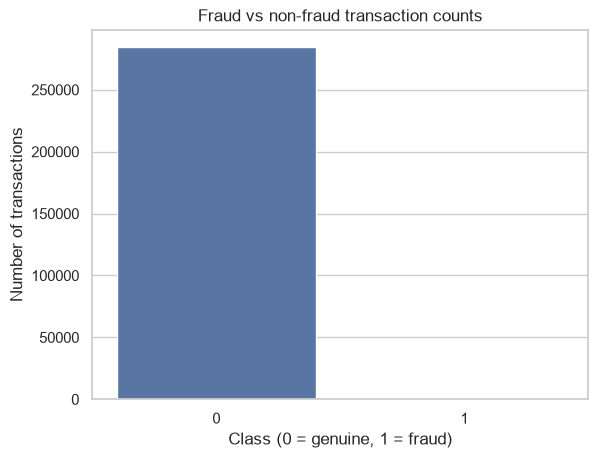

In [13]:
sns.countplot(data=fraud_df, x='Class')
plt.title('Fraud vs non-fraud transaction counts')
plt.xlabel('Class (0 = genuine, 1 = fraud)')
plt.ylabel('Number of transactions')
plt.show()

# Feature Selection and Train/Test Split

In this section, first we extract the independent variables (features) by removing the column assigned as the dependent variable (target) that we want to predict. Then, we split the dataset into 70% training and 30% testing data. We also use stratify=y_fraud because legitimate transactions are much more common than fraudulent transactions, so we maintain similar proportions of both classes in the training and testing datasets for more reliable model evaluation.

In [14]:
X_fraud = fraud_df.drop(columns='Class')
y_fraud = fraud_df['Class']

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_fraud, y_fraud, test_size=0.30,
    random_state=RANDOM_STATE, stratify=y_fraud)

print('Training rows:', len(Xf_train))
print('Testing rows:', len(Xf_test))
print('Train fraud labels:', yf_train.value_counts().to_dict())
print('Test fraud labels:', yf_test.value_counts().to_dict())


Training rows: 199364
Testing rows: 85443
Train fraud labels: {0: 199020, 1: 344}
Test fraud labels: {0: 85295, 1: 148}


# Data Preprocessing and Model Training

In this section, I use a pipeline that includes imputation, standardization, and Logistic Regression. Then, I train the model using the training dataset. After training, the model uses the testing data to make predictions, which we compare with the actual results to evaluate how well the model performs.

In [15]:
fraud_model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000,
                                 class_weight='balanced',
                                 random_state=RANDOM_STATE))
])
fraud_model.fit(Xf_train, yf_train)
yf_pred = fraud_model.predict(Xf_test)
yf_scores = fraud_model.predict_proba(Xf_test)[:, 1]
print('Logistic regression model trained.')


Logistic regression model trained.


### Logistic Regression Model Evaluation

In this section, I check how well the model predicts fraud or non-fraud transactions using accuracy, precision, recall, F1-score, ROC AUC, and average precision. Then, I use the classification report to see how the model performs for each class. Finally, I use the confusion matrix to compare the actual and predicted results and check how many predictions are correct or incorrect.

Accuracy: 0.9786
Precision: 0.0671
Recall: 0.8784
F1 score: 0.1247
ROC AUC: 0.9681
Average precision (PR AUC): 0.705
Classification report:               precision    recall  f1-score   support

           0       1.00      0.98      0.99     85295
           1       0.07      0.88      0.12       148

    accuracy                           0.98     85443
   macro avg       0.53      0.93      0.56     85443
weighted avg       1.00      0.98      0.99     85443



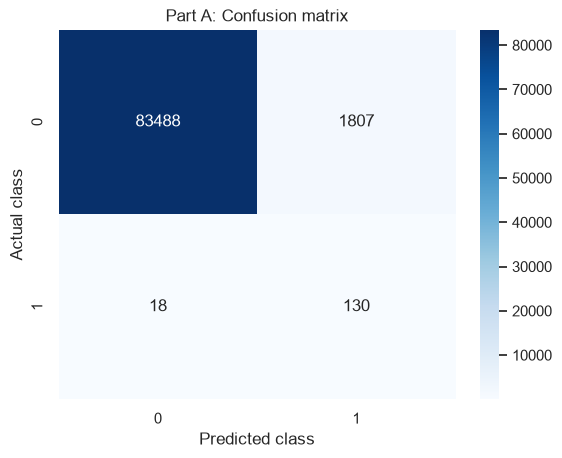

In [16]:
print('Accuracy:', round(accuracy_score(yf_test, yf_pred), 4))
print('Precision:', round(precision_score(yf_test, yf_pred,
                                         zero_division=0), 4))
print('Recall:', round(recall_score(yf_test, yf_pred,
                                   zero_division=0), 4))
print('F1 score:', round(f1_score(yf_test, yf_pred,
                                 zero_division=0), 4))
print('ROC AUC:', round(roc_auc_score(yf_test, yf_scores), 4))
print('Average precision (PR AUC):',
      round(average_precision_score(yf_test, yf_scores), 4))
print('Classification report:',
      classification_report(yf_test, yf_pred, zero_division=0))

cm = confusion_matrix(yf_test, yf_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Part A: Confusion matrix')
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.show()


# Findings — Logistic Regression Model

The model has high accuracy (97.86%) and recall (87.84%), which means it predicts most transactions correctly and detects most fraud cases. However, precision (6.71%) and F1-score (12.47%) are low because the model incorrectly predicts many legitimate transactions as fraud. ROC AUC (0.9681) and average precision (0.7050) show that the model can separate and rank fraudulent transactions well. Overall, the model detects most fraud cases but also creates many false alarms, so accuracy alone is not enough to evaluate the model.

# PART B — INSURANCE COST PREDICTION

## Exploratory Data Analysis (EDA) and Data Preprocessing Checks

In this section, I am loading the insurance dataset and performing Exploratory Data Analysis (EDA) by inspecting the DataFrame, checking null values and duplicated rows. I also check the data before preprocessing, identify the columns and their data types, and calculate summary statistics such as mean, minimum, and maximum values. These results help me understand the insurance dataset and check for possible data quality issues before training the model.

In [17]:
ins_df = pd.read_csv('data/insurance.csv')
print('Shape:', ins_df.shape)
display(ins_df.head())
ins_df.info()
print('Missing values by column:')
print(ins_df.isnull().sum())
print('Duplicates:', ins_df.duplicated().sum())
display(ins_df.describe())


Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
Missing values by column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicates: 1


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## Insurance Charges Analysis

- Insurance charges are right-skewed.
- Smokers have much higher median and average charges than non-smokers.
- Non-smokers have several high-charge outliers.

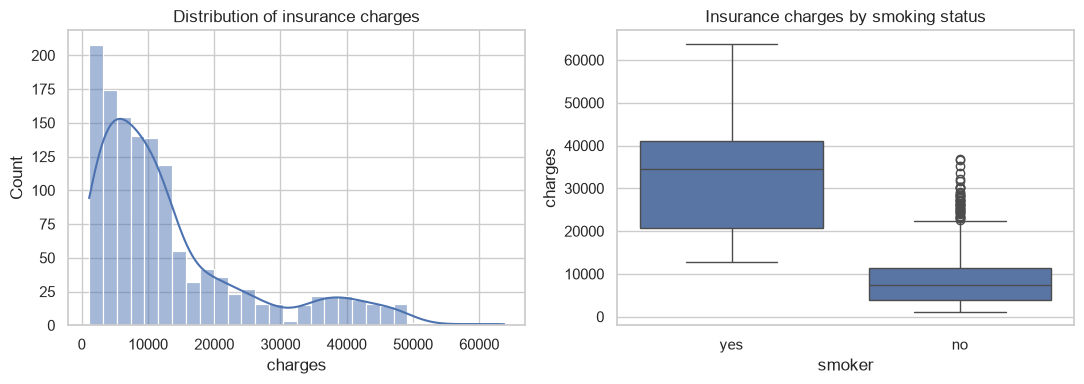

Mean charges by smoker:
smoker
no      8434.27
yes    32050.23
Name: charges, dtype: float64


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(ins_df['charges'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribution of insurance charges')
sns.boxplot(data=ins_df, x='smoker', y='charges', ax=axes[1])
axes[1].set_title('Insurance charges by smoking status')
plt.tight_layout()
plt.show()

print('Mean charges by smoker:')
print(ins_df.groupby('smoker')['charges'].mean().round(2))


### Observation

- Insurance charges are right-skewed.
- Smokers have much higher insurance charges than non-smokers.
- Most people have lower charges, while a few have very high charges.

### Train-Test Split

- **X:** Independent variables (features).
- **y:** Dependent variable (`charges`).
- Split the data into 70% training and 30% testing.
- `random_state` ensures reproducibility.

In [19]:
X_ins = ins_df.drop(columns='charges')
y_ins = ins_df['charges']

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_ins, y_ins, test_size=0.30,
    random_state=RANDOM_STATE)
print('Training rows:', len(Xi_train))
print('Testing rows:', len(Xi_test))

Training rows: 936
Testing rows: 402


## Data Preprocessing and Model Training using pipeline

- Separate features into **numerical** and **categorical** columns.
- Use **Pipeline** to handle missing values, standardize numerical features, and one-hot encode categorical features.
- Use **ColumnTransformer** to apply the appropriate transformations to each column group.
- Create another **Pipeline** to combine preprocessing with the **Linear Regression** model.
- Train the model on the training data and predict insurance charges using the test data.

In [20]:
num_cols = ['age', 'bmi', 'children']
cat_cols = ['sex', 'smoker', 'region']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

ins_preprocess = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

ins_model = Pipeline(steps=[
    ('preprocess', ins_preprocess),
    ('model', LinearRegression())
])
ins_model.fit(Xi_train, yi_train)
yi_pred = ins_model.predict(Xi_test)
print('Linear regression model trained.')


Linear regression model trained.


### Observation 
We use pipelines and ColumnTransformer to automatically preprocess different types of data and train the model consistently while preventing data leakage.

## Model Evaluation

- Evaluate model performance using MAE, RMSE, and R².
- Compare actual and predicted insurance charges.
- Visualize predictions using a scatterplot.
- Points closer to the red dashed line indicate better predictions.

MAE: 4,145.45
RMSE: 5,812.10
R-squared: 0.7696


,Actual,Predicted,Error
0,9095.07,9016.37,78.70
1,5272.18,7019.98,-1747.80
2,29330.98,36870.83,-7539.85
3,9301.89,9518.54,-216.64
4,33750.29,26974.03,6776.26
5,4536.26,11080.85,-6544.59
6,2117.34,-40.62,2157.96
7,14210.54,17192.23,-2981.70
8,3732.63,974.95,2757.67
9,10264.44,11329.96,-1065.52


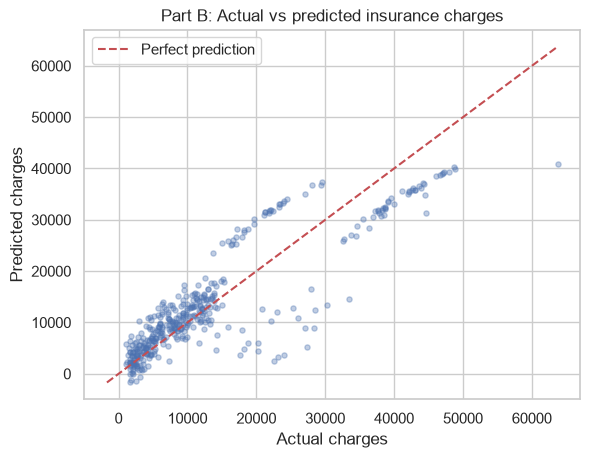

In [21]:
mae = mean_absolute_error(yi_test, yi_pred)
rmse = np.sqrt(mean_squared_error(yi_test, yi_pred))
r2 = r2_score(yi_test, yi_pred)

print(f'MAE: {mae:,.2f}')
print(f'RMSE: {rmse:,.2f}')
print(f'R-squared: {r2:.4f}')

comparison = pd.DataFrame({
    'Actual': yi_test.to_numpy(),
    'Predicted': yi_pred,
    'Error': yi_test.to_numpy() - yi_pred
})
display(comparison.head(10).round(2))

plt.scatter(yi_test, yi_pred, alpha=0.35, s=14)
lims = [min(yi_test.min(), yi_pred.min()),
        max(yi_test.max(), yi_pred.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual charges')
plt.ylabel('Predicted charges')
plt.title('Part B: Actual vs predicted insurance charges')
plt.legend()
plt.show()


### Observation

The model is doing quite well with an R² score of 0.77, which means it explains about 77% of the variation in insurance charges. However, the MAE of $4,145 shows that there are still some prediction errors, so the model can be improved.

##  Prediction for a New Customer

- Create a new customer with age, BMI, smoking status, and other features.
- Use the trained Linear Regression model to predict their insurance charges.
- Display the predicted charge rounded to two decimal places.

In [22]:
new_customer = pd.DataFrame([{
    'age': 35, 'sex': 'female', 'bmi': 27.5,
    'children': 1, 'smoker': 'no', 'region': 'northwest'
}])
print('Example predicted charge:',
      round(float(ins_model.predict(new_customer)[0]), 2))


Example predicted charge: 6303.55


### Observation

The model predicts an insurance charge of 6,303.55 for the new customer based on their age, BMI, smoking status, and other features.